In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

data_path = Path('../data/processed/chennai_house_price_prediction_cleaned.csv')

df = pd.read_csv(data_path)

print(df.shape)

df.head()

(7109, 19)


,PRT_ID,AREA,INT_SQFT,DIST_MAINROAD,N_BEDROOM,N_BATHROOM,N_ROOM,SALE_COND,PARK_FACIL,BUILDTYPE,UTILITY_AVAIL,STREET,MZZONE,QS_ROOMS,QS_BATHROOM,QS_BEDROOM,QS_OVERALL,COMMIS,SALES_PRICE
0,P03210,Karapakkam,1004,131,1.0,1.0,3,AbNormal,Yes,Commercial,AllPub,Paved,A,4.0,3.9,4.9,4.330,144400,7600000
1,P09411,Anna Nagar,1986,26,2.0,1.0,5,AbNormal,No,Commercial,AllPub,Gravel,RH,4.9,4.2,2.5,3.765,304049,21717770
2,P01812,Adyar,909,70,1.0,1.0,3,AbNormal,Yes,Commercial,ELO,Gravel,RL,4.1,3.8,2.2,3.090,92114,13159200
3,P05346,Velachery,1855,14,3.0,2.0,5,Family,No,Others,NoSewr,Paved,I,4.7,3.9,3.6,4.010,77042,9630290
4,P06210,Karapakkam,1226,84,1.0,1.0,3,AbNormal,Yes,Others,AllPub,Gravel,C,3.0,2.5,4.1,3.290,74063,7406250


In [3]:
# Identify the numerical columns
numerical_cols = df.select_dtypes(include='number').columns.tolist()

print('Numerical Columns:')

for col in numerical_cols:
    print(col)

Numerical Columns:
INT_SQFT
DIST_MAINROAD
N_BEDROOM
N_BATHROOM
N_ROOM
QS_ROOMS
QS_BATHROOM
QS_BEDROOM
QS_OVERALL
COMMIS
SALES_PRICE


In [11]:
pd.set_option('display.float_format', '{:,.2f}'.format)
df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
INT_SQFT,"7,109.00","1,382.07",457.41,500.00,993.00,"1,373.00","1,744.00","2,500.00"
DIST_MAINROAD,"7,109.00",99.60,57.40,0.00,50.00,99.00,148.00,200.00
N_BEDROOM,"7,108.00",1.64,0.80,1.00,1.00,1.00,2.00,4.00
N_BATHROOM,"7,104.00",1.21,0.41,1.00,1.00,1.00,1.00,2.00
N_ROOM,"7,109.00",3.69,1.02,2.00,3.00,4.00,4.00,6.00
QS_ROOMS,"7,109.00",3.52,0.89,2.00,2.70,3.50,4.30,5.00
QS_BATHROOM,"7,109.00",3.51,0.90,2.00,2.70,3.50,4.30,5.00
QS_BEDROOM,"7,109.00",3.49,0.89,2.00,2.70,3.50,4.30,5.00
QS_OVERALL,"7,061.00",3.50,0.53,2.00,3.13,3.50,3.89,4.97
COMMIS,"7,109.00","141,005.73","78,768.09","5,055.00","84,219.00","127,628.00","184,506.00","495,405.00"


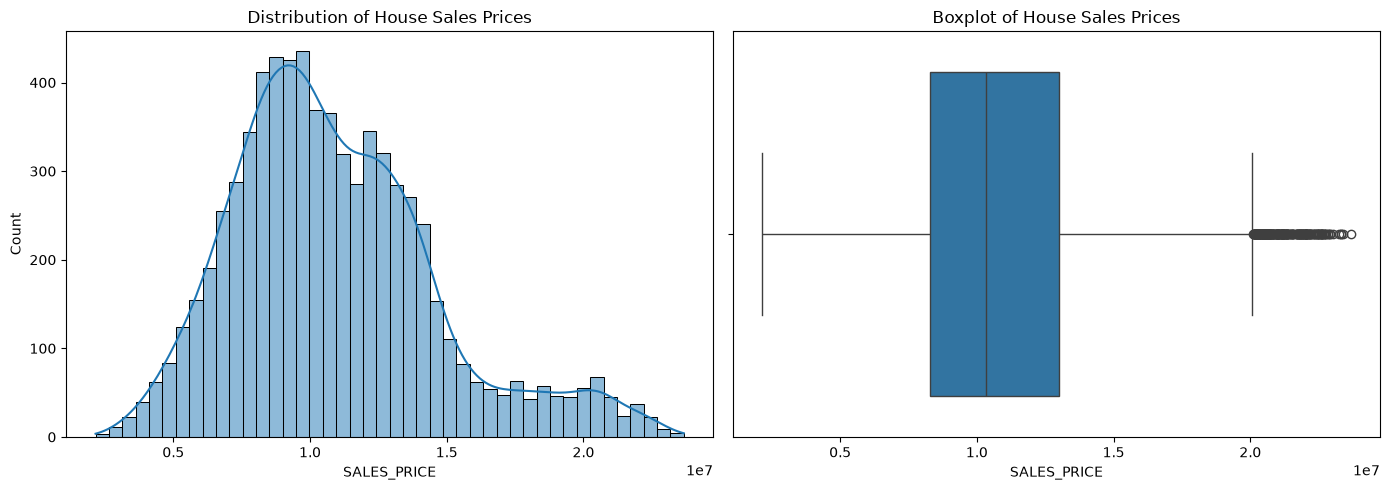

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="SALES_PRICE",
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribution of House Sales Prices")

sns.boxplot(
    data=df,
    x="SALES_PRICE",
    ax=axes[1]
)

axes[1].set_title("Boxplot of House Sales Prices")

plt.tight_layout()
plt.show()

####  Calculate the IQR Boundaries

In [13]:
# Calculate quartiles
Q1 = df["SALES_PRICE"].quantile(0.25)
Q3 = df["SALES_PRICE"].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1:,.2f}")
print(f"Q3: {Q3:,.2f}")
print(f"IQR: {IQR:,.2f}")
print(f"Lower bound: {lower_bound:,.2f}")
print(f"Upper bound: {upper_bound:,.2f}")

Q1: 8,272,100.00
Q3: 12,993,900.00
IQR: 4,721,800.00
Lower bound: 1,189,400.00
Upper bound: 20,076,600.00


#### Count the Potential Outliers

In [15]:
# Identify potential outliers
potential_outliers = df[
    (df["SALES_PRICE"] < lower_bound) |
    (df["SALES_PRICE"] > upper_bound)
]

print("Total records:", len(df))

print("Potential outliers:", len(potential_outliers))

print("Percentage of potential outliers:", round(len(potential_outliers) / len(df) * 100,2),"%")

Total records: 7109
Potential outliers: 228
Percentage of potential outliers: 3.21 %


In [20]:
# Inspect the Actual Records
potential_outliers.sort_values(by="SALES_PRICE", ascending=False).head(20)

,PRT_ID,AREA,INT_SQFT,DIST_MAINROAD,N_BEDROOM,N_BATHROOM,N_ROOM,SALE_COND,PARK_FACIL,BUILDTYPE,UTILITY_AVAIL,STREET,MZZONE,QS_ROOMS,QS_BATHROOM,QS_BEDROOM,QS_OVERALL,COMMIS,SALES_PRICE
837,P08983,T Nagar,1925,177,2.00,1.00,5,Normal Sale,Yes,Commercial,AllPub,Gravel,RM,3.50,4.60,3.60,3.82,378677,23667340
6336,P02996,Anna Nagar,1916,15,2.00,1.00,5,Normal Sale,Yes,Commercial,AllPub,Gravel,RM,4.30,2.90,2.50,3.23,444749,23407860
6164,P00067,Anna Nagar,1993,60,2.00,1.00,5,AdjLand,No,Commercial,AllPub,Gravel,RM,4.90,2.90,4.90,4.40,163202,23314580
125,P09293,T Nagar,1973,63,2.00,1.00,5,Family,Yes,Commercial,AllPub,Gravel,RM,2.60,2.90,4.90,3.71,116535,23307000
4779,P09521,T Nagar,1921,168,2.00,1.00,5,Normal Sale,Yes,Commercial,ELO,Gravel,RM,3.70,3.60,4.30,3.94,348714,23247590
7076,P00714,T Nagar,1921,188,2.00,1.00,5,Family,Yes,Commercial,NoSeWa,Gravel,RM,4.80,2.70,3.70,3.78,138081,23013500
2974,P06641,T Nagar,1972,85,2.00,1.00,5,Family,Yes,Commercial,ELO,Gravel,RM,3.30,3.50,4.50,3.89,297941,22918500
1099,P00935,Anna Nagar,1969,76,2.00,1.00,5,Normal Sale,Yes,Commercial,NoSeWa,Paved,RM,4.60,4.40,2.10,3.55,183332,22916500
3202,P06540,T Nagar,1991,139,2.00,1.00,5,AbNormal,Yes,Commercial,AllPub,Gravel,RH,4.20,2.90,4.20,3.88,137117,22852890
572,P08419,Anna Nagar,1976,82,2.00,1.00,5,AbNormal,Yes,Commercial,NoSeWa,Gravel,RL,2.50,2.40,2.80,2.60,342437,22829130


In [17]:
# Compare potential outliers with the remaining records

df["PRICE_GROUP"] = np.where(
    df["SALES_PRICE"] > upper_bound,
    "Potential High-Price Outlier",
    "Other"
)

comparison = df.groupby("PRICE_GROUP")[
    ["SALES_PRICE", "INT_SQFT", "N_BEDROOM", "N_ROOM"]
].median()

display(comparison)

,SALES_PRICE,INT_SQFT,N_BEDROOM,N_ROOM
PRICE_GROUP,,,,
Other,"10,172,480.00","1,323.00",1.00,4.00
Potential High-Price Outlier,"21,059,240.00","1,881.00",2.00,5.00


In [21]:
potential_outliers['AREA'].value_counts()

AREA
Anna Nagar    124
T Nagar       100
KK Nagar        4
Name: count, dtype: int64

In [22]:
# Count properties in the complete dataset
all_area_counts = df["AREA"].value_counts()

# Count potential high-price outliers by area
outlier_area_counts = potential_outliers["AREA"].value_counts()

# Combine the counts
area_comparison = pd.DataFrame({
    "Total_Properties": all_area_counts,
    "Potential_Outliers": outlier_area_counts
}).fillna(0)

area_comparison["Potential_Outliers"] = (
    area_comparison["Potential_Outliers"].astype(int)
)

# Calculate the percentage of properties flagged in each area
area_comparison["Outlier_Percentage"] = (
    area_comparison["Potential_Outliers"]
    / area_comparison["Total_Properties"]
    * 100
)

display(
    area_comparison.sort_values(
        "Potential_Outliers",
        ascending=False
    )
)

,Total_Properties,Potential_Outliers,Outlier_Percentage
AREA,,,
Anna Nagar,788,124,15.74
T Nagar,501,100,19.96
KK Nagar,997,4,0.40
Chrompet,1702,0,0.00
Adyar,774,0,0.00
Karapakkam,1366,0,0.00
Velachery,981,0,0.00


In [25]:
features_to_inspect = [
    "AREA",
    "INT_SQFT",
    "N_BEDROOM",
    "N_BATHROOM",
    "N_ROOM",
    "QS_ROOMS",
    "QS_BATHROOM",
    "QS_BEDROOM",
    "QS_OVERALL",
    "SALES_PRICE"
]

display(
    potential_outliers[features_to_inspect]
    .sort_values(
        "SALES_PRICE",
        ascending=False
    )
    .head(20)
)

,AREA,INT_SQFT,N_BEDROOM,N_BATHROOM,N_ROOM,QS_ROOMS,QS_BATHROOM,QS_BEDROOM,QS_OVERALL,SALES_PRICE
837,T Nagar,1925,2.00,1.00,5,3.50,4.60,3.60,3.82,23667340
6336,Anna Nagar,1916,2.00,1.00,5,4.30,2.90,2.50,3.23,23407860
6164,Anna Nagar,1993,2.00,1.00,5,4.90,2.90,4.90,4.40,23314580
125,T Nagar,1973,2.00,1.00,5,2.60,2.90,4.90,3.71,23307000
4779,T Nagar,1921,2.00,1.00,5,3.70,3.60,4.30,3.94,23247590
7076,T Nagar,1921,2.00,1.00,5,4.80,2.70,3.70,3.78,23013500
2974,T Nagar,1972,2.00,1.00,5,3.30,3.50,4.50,3.89,22918500
1099,Anna Nagar,1969,2.00,1.00,5,4.60,4.40,2.10,3.55,22916500
3202,T Nagar,1991,2.00,1.00,5,4.20,2.90,4.20,3.88,22852890
572,Anna Nagar,1976,2.00,1.00,5,2.50,2.40,2.80,2.60,22829130


In [26]:
# Create a temporary grouping
df["PRICE_GROUP"] = np.where(
    df["SALES_PRICE"] > upper_bound,
    "Potential High-Price Outlier",
    "Other Properties"
)

comparison = df.groupby("PRICE_GROUP")[
    [
        "SALES_PRICE",
        "INT_SQFT",
        "N_BEDROOM",
        "N_BATHROOM",
        "N_ROOM",
        "QS_OVERALL"
    ]
].median()

display(comparison)

,SALES_PRICE,INT_SQFT,N_BEDROOM,N_BATHROOM,N_ROOM,QS_OVERALL
PRICE_GROUP,,,,,,
Other Properties,"10,172,480.00","1,323.00",1.00,1.00,4.00,3.50
Potential High-Price Outlier,"21,059,240.00","1,881.00",2.00,1.00,5.00,3.52


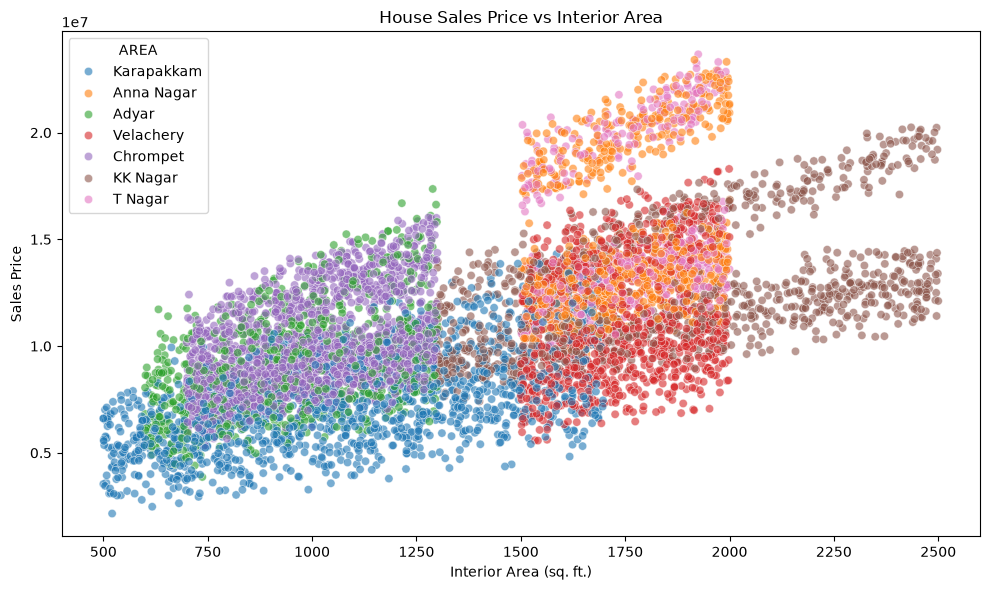

In [27]:
# Investigate the relationship between price and interior area

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="INT_SQFT",
    y="SALES_PRICE",
    hue="AREA",
    alpha=0.6
)

plt.title("House Sales Price vs Interior Area")
plt.xlabel("Interior Area (sq. ft.)")
plt.ylabel("Sales Price")
plt.tight_layout()
plt.show()


> Our current conclusion: We have not found sufficient evidence to remove the high-price observations.

In [29]:
## We should investigate whether the potential outliers are unusual within their respective locations, 
# rather than only relative to the entire dataset.

# Compare prices within each area

# Compare sales prices across areas

area_price_summary = df.groupby("AREA")["SALES_PRICE"].agg(["count", "min", "median", "max"])

area_price_summary = area_price_summary.sort_values("median", ascending=False)

display(area_price_summary)

,count,min,median,max
AREA,,,,
T Nagar,501,9433610,"14,049,650.00",23667340
Anna Nagar,788,9593040,"13,727,895.00",23407860
KK Nagar,997,7410200,"12,146,740.00",20246360
Velachery,981,5574400,"10,494,410.00",18298710
Chrompet,1702,5340900,"9,606,725.00",16026600
Adyar,774,3869180,"8,878,350.00",17360470
Karapakkam,1366,2156875,"7,043,125.00",14486250


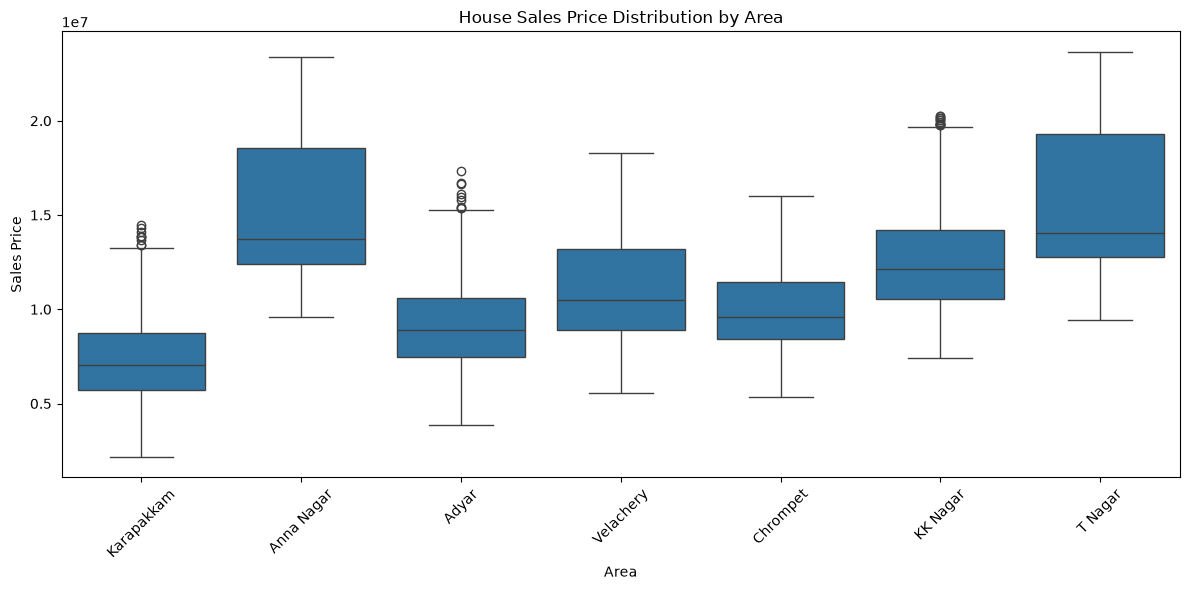

In [30]:
# Visualize prices by area

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="AREA",
    y="SALES_PRICE"
)

plt.title("House Sales Price Distribution by Area")
plt.xlabel("Area")
plt.ylabel("Sales Price")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
def calculate_iqr_outliers(group):
    q1 = group["SALES_PRICE"].quantile(0.25)
    q3 = group["SALES_PRICE"].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    high_outliers = group["SALES_PRICE"] > upper_bound
    low_outliers = group["SALES_PRICE"] < lower_bound

    return pd.Series({
        "Property_Count": len(group),
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Low_Outliers": low_outliers.sum(),
        "High_Outliers": high_outliers.sum(),
        "Total_Outliers": (
            low_outliers | high_outliers
        ).sum()
    })


area_outlier_summary = (
    df.groupby("AREA")
    .apply(calculate_iqr_outliers)
    .sort_values("Total_Outliers", ascending=False)
)

display(area_outlier_summary)


,Property_Count,Lower_Bound,Upper_Bound,Low_Outliers,High_Outliers,Total_Outliers
AREA,,,,,,
KK Nagar,997.00,"5,044,230.00","19,717,110.00",0.00,12.00,12.00
Karapakkam,"1,366.00","1,203,640.62","13,269,765.62",0.00,9.00,9.00
Adyar,774.00,"2,785,579.38","15,321,654.38",0.00,9.00,9.00
Chrompet,"1,702.00","3,842,887.50","16,035,247.50",0.00,0.00,0.00
Anna Nagar,788.00,"3,226,398.75","27,729,908.75",0.00,0.00,0.00
T Nagar,501.00,"2,973,420.00","29,057,340.00",0.00,0.00,0.00
Velachery,981.00,"2,459,850.00","19,653,930.00",0.00,0.00,0.00


In [32]:
# Inspect the 30 Area-Specific Outliers
area_specific_outliers = []

for area, group in df.groupby("AREA"):

    q1 = group["SALES_PRICE"].quantile(0.25)
    q3 = group["SALES_PRICE"].quantile(0.75)

    iqr = q3 - q1

    upper_bound = q3 + 1.5 * iqr

    high_outliers = group[
        group["SALES_PRICE"] > upper_bound
    ]

    area_specific_outliers.append(high_outliers)

area_specific_outliers = pd.concat(
    area_specific_outliers
)

print(
    "Number of area-specific high-price outliers:",
    len(area_specific_outliers)
)

Number of area-specific high-price outliers: 30


In [33]:
# Inspect their features

features_to_inspect = [
    "AREA",
    "INT_SQFT",
    "N_BEDROOM",
    "N_BATHROOM",
    "N_ROOM",
    "QS_ROOMS",
    "QS_BATHROOM",
    "QS_BEDROOM",
    "QS_OVERALL",
    "SALES_PRICE"
]

display(
    area_specific_outliers[
        features_to_inspect
    ].sort_values(
        "SALES_PRICE",
        ascending=False
    )
)

,AREA,INT_SQFT,N_BEDROOM,N_BATHROOM,N_ROOM,QS_ROOMS,QS_BATHROOM,QS_BEDROOM,QS_OVERALL,SALES_PRICE
315,KK Nagar,2435,4.00,2.00,6,2.60,4.00,4.10,3.62,20246360
5812,KK Nagar,2496,4.00,2.00,6,3.60,4.20,3.90,3.90,20231160
5273,KK Nagar,2414,4.00,2.00,6,4.10,4.80,2.80,3.79,20151580
2395,KK Nagar,2458,4.00,2.00,6,5.00,2.60,3.10,3.52,20139900
843,KK Nagar,2455,4.00,2.00,6,3.80,3.80,3.80,3.80,20063100
6556,KK Nagar,2491,4.00,2.00,6,4.40,2.50,5.00,4.07,20016180
3464,KK Nagar,2329,4.00,2.00,6,2.10,3.60,4.70,3.59,19959560
6688,KK Nagar,2454,4.00,2.00,6,3.80,2.70,2.80,3.07,19824800
282,KK Nagar,2360,4.00,2.00,6,2.00,3.90,4.60,3.61,19816180
6446,KK Nagar,2451,4.00,2.00,6,3.40,3.30,4.40,3.77,19807800


In [35]:
# Diagnostic analysis only
area_specific_outliers = area_specific_outliers.copy()

area_specific_outliers["PRICE_PER_SQFT_DIAGNOSTIC"] = (
    area_specific_outliers["SALES_PRICE"]
    / area_specific_outliers["INT_SQFT"]
)

display(
    area_specific_outliers[
        [
            "AREA",
            "INT_SQFT",
            "SALES_PRICE",
            "PRICE_PER_SQFT_DIAGNOSTIC"
        ]
    ].sort_values(
        "PRICE_PER_SQFT_DIAGNOSTIC",
        ascending=False
    )
)

,AREA,INT_SQFT,SALES_PRICE,PRICE_PER_SQFT_DIAGNOSTIC
3831,Adyar,1215,16693265,"13,739.31"
4073,Adyar,1289,17360470,"13,468.17"
3412,Adyar,1182,15389035,"13,019.49"
3161,Adyar,1182,15381325,"13,012.97"
4568,Adyar,1203,15442540,"12,836.69"
5380,Adyar,1297,16625090,"12,818.11"
4533,Adyar,1251,15965260,"12,762.00"
321,Adyar,1284,16107475,"12,544.76"
3576,Adyar,1299,15815700,"12,175.29"
4456,Karapakkam,1451,13851000,"9,545.83"


#### Outlier Analysis Summary
- The sales-price distribution was examined using a histogram and boxplot.
- The IQR method identified 228 potential high-price outliers using a global threshold.
- The flagged properties were concentrated in Anna Nagar, T Nagar, and KK Nagar.
- A comparison of sales prices against interior area suggested a positive association between property size and price.
- Price distributions were examined separately for each area.
- Area-specific IQR analysis identified 30 potential high-price outliers: 12 in KK Nagar, 9 in Adyar, and 9 in Karapakkam.
- The displayed records did not reveal obvious numerical impossibilities in their main property characteristics.
- No observations were removed solely because they were flagged by the IQR method.
- The flagged records were retained provisionally because the available evidence did not establish that their recorded values were incorrect.